# Lab 9: Quantum Phase Estimation - Unlocking the Eigenvalues of Unitary Operators

Welcome to Lab 9! In the previous lab, we mastered the Quantum Fourier Transform (QFT), a powerful subroutine that allows us to move between the computational and Fourier bases. We noted that its true power lies not in isolation, but as a core component in more advanced algorithms. Today, we will see its first major application in the **Quantum Phase Estimation (QPE)** algorithm.

Imagine you have a quantum operation, represented by a unitary matrix `U`, and a quantum state `|ψ>` which is an *eigenvector* of that operation. This means that applying `U` to `|ψ>` only changes its global phase: `U|ψ> = e^(2πiφ)|ψ>`. The value `φ` is the "phase," and it contains crucial information about the operator. The goal of QPE is to determine this phase `φ` with high precision.

Classically, finding eigenvalues can be a computationally hard problem. QPE provides an efficient quantum method to do so, and it serves as the foundational engine for some of the most famous quantum algorithms, including **Shor's algorithm** for factoring large numbers—an application with profound implications for cryptography.

The QPE algorithm cleverly uses the inverse QFT to extract this phase. It works by preparing a "counting" register in superposition and using it to control successive applications of the unitary `U`. This process encodes the binary representation of the phase `φ` onto the counting qubits. A final inverse QFT then transforms this phase information into a measurable computational basis state.

In this lab, we will:
*   Implement the Quantum Phase Estimation (QPE) algorithm, one of the most important quantum subroutines.
*   Use the inverse Quantum Fourier Transform (IQFT), building on our work from the previous lab, as the final key step for phase extraction.
*   Construct the controlled-unitary part of the algorithm, which methodically encodes the phase information onto a register of counting qubits.
*   Apply the algorithm to find the phase of a simple gate (the S gate) with a known eigenvalue.
*   Demonstrate how to increase the algorithm's precision by adding more qubits to the counting register, allowing us to estimate more complex, arbitrary phases.
*   Use the **`qasm_simulator`** to run the circuit and interpret the measurement results as the binary representation of the unknown phase.

Let's harness the power of the QFT to uncover the hidden properties of quantum operators and build one of the most fundamental algorithms in quantum computation.

In [3]:
%pip install qiskit
%pip install qiskit_aer
%pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 37.7 MB/s  0:00:00


In [4]:
import qiskit
from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library
from qiskit.quantum_info import Operator
from qiskit.circuit.library import ZGate


## Function for Inverse QFT

In [5]:
def qft_dagger(qc, n):
    for qubit in range(n//2):
        qc.swap(qubit, n-qubit-1)
    for j in range(n):
        for m in range(j):
            qc.cp(-pi/float(2**(j-m)), m, j)
        qc.h(j)

## Function to Compute QPE

In [6]:
# Function to calculate QPE
# Target Qubits helps to rotate the First Register Qubits with appropriate phase
# Control Qubit is the First Register Qubits
def qpe_main(circuit, angle, target_qubits):
    repetitions = 1
    for control_qubit in range(target_qubits):
        for i in range(repetitions):
            circuit.cp(angle, control_qubit, target_qubits);
        repetitions *= 2

## QPE Code to Find S Gate Phase Value of 1/4

Example to extract the eigenvalue of the single-qubit quantum $S$ gate :

Remember that the expected $\theta$ is:

$$S|1\rangle = e^\frac{i\pi}{2}|1\rangle\rightarrow QPE|1\rangle = e^{2\pi i \theta}|1\rangle$$

If we compare both expressions above and solve the linear equation of one incognita that arises, we obtain $\theta=\frac{1}{4}$.

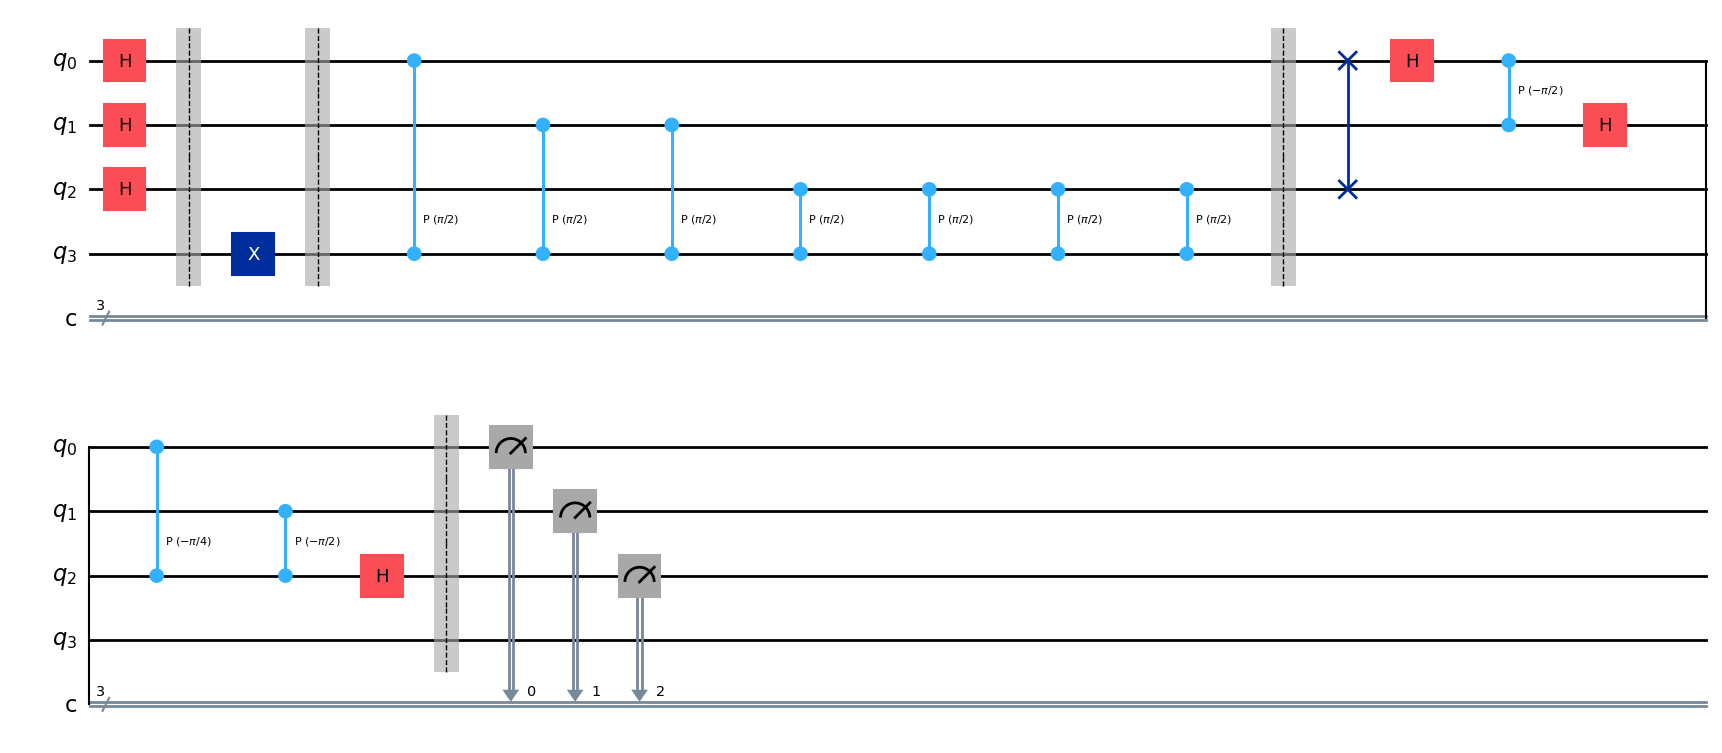

In [7]:
#this angle is the same as in the matrix of S Gate
angle = pi/2

# initialize our Quantum Circuit
qpe = QuantumCircuit(4, 3)

# Apply Hadamards to the First Register Qubits (Counting Register)
for i in range(3):
    qpe.h(i)
qpe.barrier()

# Initialize the Second Register to |1>
qpe.x(3)
qpe.barrier()

# Apply the QPE Function
qpe_main(qpe, angle, 3)
qpe.barrier()

# Apply the Inverse QFT
qft_dagger(qpe, 3)
qpe.barrier()

# Measure all the First Register Qubits which stores the Phase value
for i in range(3):
    qpe.measure(i, i)

# Visualize our Circuit
qpe.draw('mpl')

## Simulating the QPE for S Gate Circuit


Total counts are: {'010': 1000}


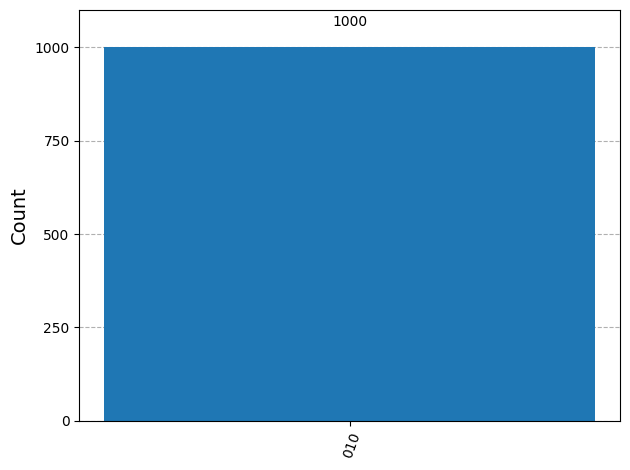

In [8]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qpe, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qpe)
print("\nTotal counts are:",counts)

# Plot the histogram
plot_histogram(counts)

We have obtained the expected result! We obtain $010_{binary} = 0\cdot(2^{2})+1\cdot(2^{1})+0\cdot(2^{0}) = 2_{decimal}$. The solution is $\frac{solution}{2^n}$. So, substituing the answer is: $\frac{2}{2^3}= \frac{1}{4}$. The expected theta!

## QPE for General $\theta$

The following code is intended to use the QPE algorithm for a generalized $\theta$ and solve the phase of the follwing operator for the $|1\rangle$ state:

$$ U = \begin{pmatrix}
1 & 0 \\
0 & e^{\frac{2\pi i}{5}}
\end{pmatrix}$$



In [9]:
# Another example of a generalizing QPE algorithm for a phase factor of 1/5

# We would require 8 qubits to have a precision of thousandth (10^-3)

angle = 2*pi/5 #this angle is the same as in the matrix
control_qubits = 8

# initialize our QuantumCircuit
qpe_1 = QuantumCircuit(control_qubits+1, control_qubits)

# Apply Hadamards to the First Register Qubits (Counting Register)
for i in range(control_qubits):
    qpe_1.h(i)

# Initialize the Second Register to |1>
qpe_1.x(control_qubits)
qpe_1.barrier()

# Apply the QPE Function
qpe_main(qpe_1, angle, control_qubits) # Calling the QPE Function
qpe_1.barrier()

# Apply the Inverse QFT
qft_dagger(qpe_1, control_qubits)
qpe_1.barrier()

# Measure all the First Register Qubits which stores the Phase value
for i in range(control_qubits):
    qpe_1.measure(i, i)

# Visualize our Circuit
qpe_1.draw('mpl')


Total counts are: {'01000111': 1, '00101100': 1, '00111000': 2, '10011001': 1, '01100000': 1, '01000010': 1, '00110111': 3, '00110010': 22, '00110100': 57, '00011110': 1, '00110101': 12, '00101101': 1, '00100101': 1, '00111001': 1, '00101110': 1, '00110001': 5, '00110000': 3, '00110110': 8, '00110011': 873, '00101111': 3, '00111011': 1, '00100110': 1}


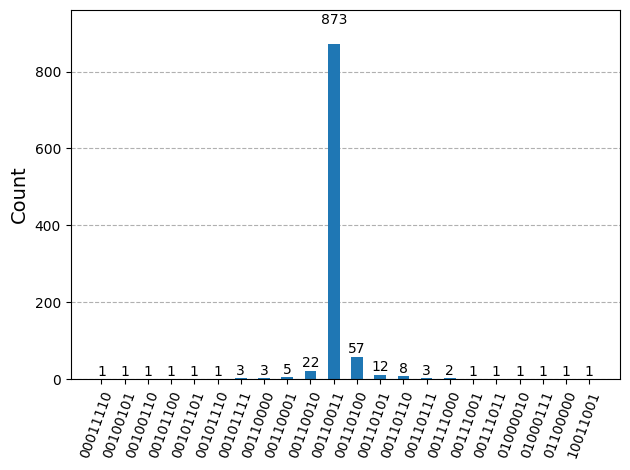

In [10]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qpe_1, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qpe_1)
print("\nTotal counts are:",counts)

# Plot the histogram
plot_histogram(counts)

We have obtained the expected result! We obtain $00110010_{binary} = 50_{decimal}$. The solution is $\frac{solution}{2^n}$. So, substituing the answer is: $\frac{50}{2^8}= \frac{50}{256} = 0.195$. Appriximately $0.2$. The expected theta was $\frac{1}{5}= 0.2$. So, we got our expected theta!